# 05_B_baselines — baselines scored on VAL (test is not touched)
Fit on `train` (anomalous seasons dropped), score on `val` 2018-2021. CI = 95% bootstrap, whole expeditions resampled.

* (a) constant = train mean
* (b) rule: historical success rate of **(peak, season)**, past years only, shrunk to the peak rate and then to the global rate (`M.PeakSeasonRate`). No existing feature is peak x season: `PEAK_SUCCESS_PRIOR` is per peak only, so it is shown as an extra row (b2).
* (c) logistic regression: age + hinge max(age-40, 0), standardised numerics (median imputation + missing flag), one-hot categoricals
* (d) CatBoost default with categorical features; early stopping on a **grouped fold inside train**, not on val

Reusable code lives in `src/` (`split`, `evaluate`, `models`, `experiment_log`); this notebook only calls it and plots.

In [1]:
import os, sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

from src.split import load_features, dev_split, fit_frame, TARGET
from src.evaluate import summary_row, results_table, plot_calibration, metrics_by_group
from src import models as M
from src.experiment_log import log_experiment

N_BOOT = 1000   # bootstrap resamples of whole expeditions (lower to ~200 for a quick dry run)
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

In [2]:
df = load_features()
train, val = dev_split(df)              # the TEST rows are never loaded in this notebook
train_fit = fit_frame(train)            # fitting rows: anomalous seasons dropped
clean = ~val["ANOMALOUS_SEASON"].to_numpy()   # val view without anomalous seasons (2020, spring 2021)
print(f"train {len(train):,} (fit {len(train_fit):,}) | val {len(val):,} (clean {clean.sum():,})")
print(f"{TARGET}: train {train[TARGET].mean():.3f} | val {val[TARGET].mean():.3f} | val clean {val.loc[clean, TARGET].mean():.3f}")
print(f"model features ({len(M.MODEL_FEATURES)}): YEAR excluded; categorical: {M.cat_names(M.MODEL_FEATURES)}")

train 37,969 (fit 37,448) | val 5,042 (clean 4,236)
MSUCCESS: train 0.383 | val 0.537 | val clean 0.549
model features (34): YEAR excluded; categorical: ['SEX', 'CITIZEN', 'STATUS', 'PEAK_GROUP', 'ROUTE1', 'SEASON', 'HOST', 'AGENCY', 'HIMAL', 'REGION']


In [3]:
def evaluate_all(preds):
    """Two views: all val rows, and val without anomalous seasons."""
    all_rows = [summary_row(n, val[TARGET], p, val["EXPID"], N_BOOT) for n, p in preds.items()]
    clean_rows = [summary_row(n, val.loc[clean, TARGET], p[clean], val.loc[clean, "EXPID"], N_BOOT) for n, p in preds.items()]
    return all_rows, clean_rows

## Fit and predict on val

In [4]:
preds = {}
preds["(a) constant = train mean"] = M.constant_baseline(train_fit, val)
preds["(b) peak x season rate (past)"] = M.PeakSeasonRate().fit(train_fit).predict(val)
preds["(b2) PEAK_SUCCESS_PRIOR feature"] = M.peak_success_prior_baseline(val)
preds["(c) logreg + age hinge@40"] = M.fit_logreg(train_fit).predict(val)
cb_default = M.fit_catboost(train_fit)
preds["(d) CatBoost default"] = cb_default.predict(val)
print("CatBoost best iteration:", cb_default.best_iteration)

CatBoost best iteration: 403


## One table: val metrics with 95% CI (expedition bootstrap)

In [5]:
rows_all, rows_clean = evaluate_all(preds)
print("VAL, all rows"); display(results_table(rows_all))
print("VAL, without anomalous seasons"); display(results_table(rows_clean))
pd.concat({"val_all": results_table(rows_all), "val_no_anomalous": results_table(rows_clean)}).to_csv(ROOT / "reports" / "05_B_baselines_table.csv")

VAL, all rows


,ROC AUC,Brier,Log loss,n,mean_p
model,,,,,
(a) constant = train mean,"0.500 [0.500, 0.500]","0.271 [0.265, 0.276]","0.736 [0.724, 0.747]",5042,0.386696
(b) peak x season rate (past),"0.601 [0.569, 0.633]","0.250 [0.242, 0.256]","0.693 [0.677, 0.707]",5042,0.430918
(b2) PEAK_SUCCESS_PRIOR feature,"0.543 [0.508, 0.574]","0.274 [0.264, 0.281]","0.746 [0.724, 0.761]",5042,0.378654
(c) logreg + age hinge@40,"0.686 [0.654, 0.713]","0.228 [0.218, 0.242]","0.656 [0.630, 0.689]",5042,0.535327
(d) CatBoost default,"0.709 [0.678, 0.737]","0.221 [0.212, 0.230]","0.633 [0.611, 0.654]",5042,0.471940


VAL, without anomalous seasons


,ROC AUC,Brier,Log loss,n,mean_p
model,,,,,
(a) constant = train mean,"0.500 [0.500, 0.500]","0.274 [0.267, 0.281]","0.742 [0.729, 0.757]",4236,0.386696
(b) peak x season rate (past),"0.614 [0.587, 0.645]","0.249 [0.241, 0.257]","0.692 [0.674, 0.709]",4236,0.428657
(b2) PEAK_SUCCESS_PRIOR feature,"0.546 [0.520, 0.576]","0.278 [0.269, 0.287]","0.753 [0.734, 0.772]",4236,0.379885
(c) logreg + age hinge@40,"0.714 [0.690, 0.738]","0.217 [0.208, 0.226]","0.627 [0.604, 0.651]",4236,0.521250
(d) CatBoost default,"0.731 [0.704, 0.757]","0.214 [0.204, 0.223]","0.616 [0.594, 0.639]",4236,0.473989


## Calibration (val, all rows)

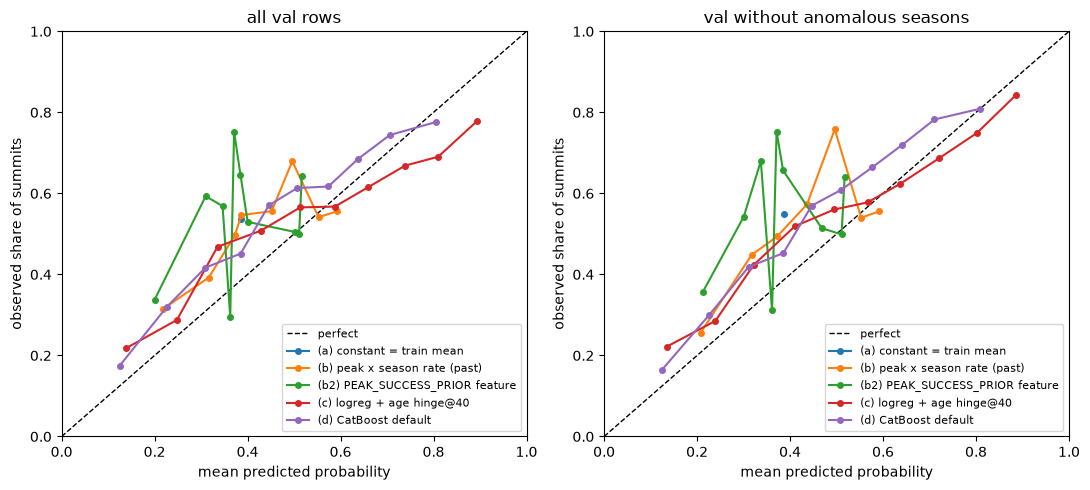

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
plot_calibration(val[TARGET], preds, ax=axes[0], title="all val rows")
plot_calibration(val.loc[clean, TARGET], {k: v[clean] for k, v in preds.items()}, ax=axes[1], title="val without anomalous seasons")
plt.tight_layout(); plt.savefig(FIG / "05_B_baselines_calibration.png", dpi=150); plt.show()

## Where does CatBoost work and where does it not? (val, all rows)

In [7]:
p = preds["(d) CatBoost default"]
for col in ["PEAK_GROUP", "SEASON", "AGE_BIN"]:
    print(f"--- by {col}"); display(metrics_by_group(val, p, col).round(3))

--- by PEAK_GROUP


,n,mean_y,mean_p,roc_auc,brier,log_loss
PEAK_GROUP,,,,,,
AMAD,1041,0.540,0.461,0.643,0.240,0.676
ANN1,76,0.684,0.441,0.709,0.252,0.706
BARU,101,0.228,0.241,0.848,0.130,0.416
CHOY,192,0.625,0.381,0.800,0.242,0.680
DHA1,162,0.185,0.399,0.774,0.176,0.528
EVER,1510,0.669,0.582,0.692,0.206,0.603
HIML,262,0.378,0.336,0.623,0.232,0.660
KANG,79,0.620,0.439,0.475,0.298,0.798
LHOT,263,0.479,0.491,0.580,0.256,0.712


--- by SEASON


,n,mean_y,mean_p,roc_auc,brier,log_loss
SEASON,,,,,,
1,2372,0.581,0.511,0.714,0.215,0.621
3,2592,0.505,0.442,0.687,0.229,0.650
4,78,0.244,0.267,0.855,0.126,0.411


--- by AGE_BIN


,n,mean_y,mean_p,roc_auc,brier,log_loss
AGE_BIN,,,,,,
25-34,1111,0.599,0.526,0.719,0.209,0.605
35-44,1514,0.581,0.519,0.690,0.221,0.633
45-54,1361,0.509,0.444,0.673,0.233,0.659
55+,774,0.386,0.338,0.690,0.216,0.624
<25,228,0.566,0.516,0.720,0.211,0.609
unknown,54,0.741,0.479,0.764,0.240,0.745


## Log to README (Experiment log) and reports/experiment_log.csv

In [8]:
notes = {
 "(a) constant = train mean": "Reference. Val success rate is higher than train, so Brier/log loss show the shift.",
 "(b) peak x season rate (past)": "Rule baseline, no ML; peak x season, past years only.",
 "(b2) PEAK_SUCCESS_PRIOR feature": "Existing feature used as probability (peak only, not season-specific).",
 "(c) logreg + age hinge@40": "Linear model with age knot at 40; YEAR excluded.",
 "(d) CatBoost default": "Default params, early stopping on a grouped fold inside train; YEAR excluded.",
}
res_all = {r["model"]: r["_res"] for r in rows_all}; res_clean = {r["model"]: r["_res"] for r in rows_clean}
for name in preds:
    log_experiment("B baseline " + name, res_all[name], res_clean[name], notes[name])
print("README.md and reports/experiment_log.csv updated")

README.md and reports/experiment_log.csv updated
